In [20]:
import sys, os
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount('/content/drive')

    if not os.path.exists("/content/project"):
        !git clone -b develop https://github.com/yegor-vin/neural-networks--project.git /content/project
    else:
        !git -C /content/project pull

    if not os.path.exists("/content/project/data"):
        !cp "/content/drive/MyDrive/asl--project/data.zip" /content/
        !unzip -q /content/data.zip -d /content/project/

    !pip install -q mediapipe wandb

    os.chdir("/content/project/src")
    if "/content/project/src" not in sys.path:
        sys.path.insert(0, "/content/project/src")


Hands found in 147764/159398 images (92.7%)
Hands found in 127441/137798 images (92.5%)
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


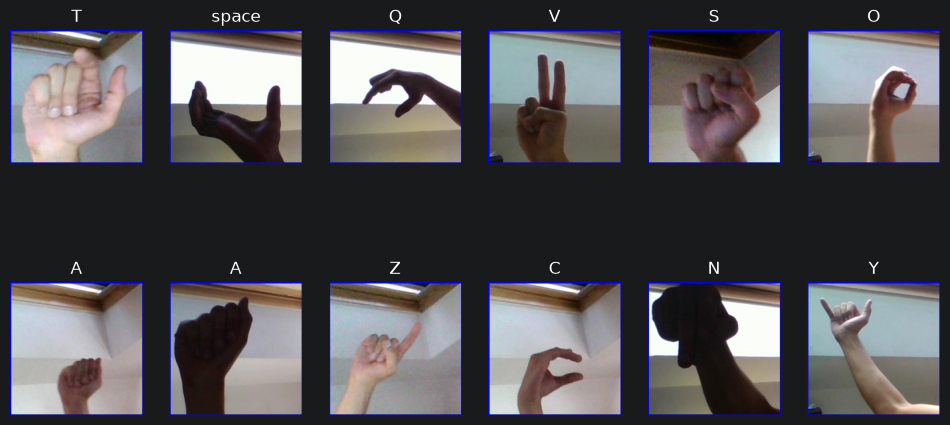

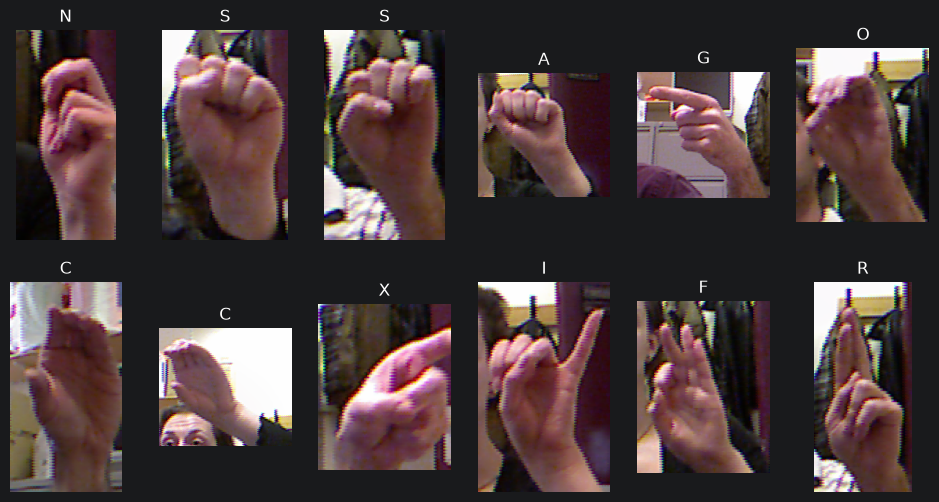

In [21]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from hand_crop import HandCropDataset, compute_boxes
import sys


IN_COLAB = "google.colab" in sys.modules
NUM_WORKERS = 2 if IN_COLAB else 0


DATA_DIR = Path("..") / "data"
TRAIN_DIR = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"
TEST_DIR = DATA_DIR / "asl_alphabet_test" / "asl_alphabet_test"
TEST_DIR_DIFF = DATA_DIR / "pugeault" / "dataset5"
HAND_BOXES_CACHE = DATA_DIR / "hand_boxes.json"
EXTRA_TRAIN_DIR = DATA_DIR / "Train_Alphabet"


def build_transforms(img_size=160, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), augment=None):
    base = [transforms.Resize((img_size, img_size))]
    post = [transforms.ToTensor(), transforms.Normalize(mean, std)]
    if augment is None:
        augment = [
            transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), shear=15),
            transforms.RandomResizedCrop(size=160, scale=(0.6, 1.0), ratio=(3/4, 4/3)),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomGrayscale(p=0.15),
            transforms.RandomApply([transforms.GaussianBlur(5)], p=0.3)
        ]
    erase = [transforms.RandomErasing(p=0.5, scale=(0.02, 0.1), ratio=(0.3, 3), value=0)]
    train_tf = transforms.Compose(base + list(augment) + post + erase)
    eval_tf = transforms.Compose(base + post)
    return train_tf, eval_tf


class PugeaultDataset(Dataset):
    def __init__(self, root, class_to_idx, persons=("A", "B", "C", "D", "E")):
        self.files, self.targets = [], []
        for person in persons:
            for letter_dir in sorted((Path(root) / person).iterdir()):
                if not letter_dir.is_dir():
                    continue
                label = class_to_idx[letter_dir.name.upper()]
                for p in sorted(letter_dir.glob("*.png")):
                    self.files.append(p)
                    self.targets.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


class ASLTestDataset(Dataset):
    def __init__(self, root, class_to_idx):
        self.files = sorted(Path(root).glob("*.jpg"))
        self.targets = [class_to_idx[p.stem.split("_")[0]] for p in self.files]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


class FileListDataset(Dataset):
    def __init__(self, samples, classes, class_to_idx):
        self.files = [Path(p) for p, _ in samples]
        self.targets = [y for _, y in samples]
        self.classes, self.class_to_idx = classes, class_to_idx

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


def get_targets(ds):
    if isinstance(ds, Subset):
        base = get_targets(ds.dataset)
        return [base[i] for i in ds.indices]
    return list(ds.targets)


class FilteredDataset(Dataset):
    def __init__(self, ds, keep, class_to_idx):
        self.ds = ds
        self.classes = list(keep)
        old_to_new = {class_to_idx[c]: i for i, c in enumerate(keep)}
        pairs = [(i, old_to_new[y]) for i, y in enumerate(get_targets(ds)) if y in old_to_new]
        self.indices = [i for i, _ in pairs]
        self.targets = [y for _, y in pairs]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, _ = self.ds[self.indices[i]]
        return img, self.targets[i]


def get_paths(ds):
    if isinstance(ds, Subset):
        base = get_paths(ds.dataset)
        return [base[i] for i in ds.indices]
    if isinstance(ds, FilteredDataset):
        base = get_paths(ds.ds)
        return [base[i] for i in ds.indices]
    if isinstance(ds, datasets.ImageFolder):
        return [p for p, _ in ds.samples]
    return list(ds.files)


class TransformedDataset(Dataset):
    def __init__(self, ds, transform):
        self.ds = ds
        self.transform = transform
        self.classes = getattr(ds, "classes", None)
        self.targets = getattr(ds, "targets", None)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, y = self.ds[i]
        return self.transform(img), y


def default_keep_classes(classes):
    return [c for c in classes if len(c) == 1 and c not in ("J", "Z")]


def build_datasets(train_tf, eval_tf, valid_size=0.2, seed=42, keep_classes=None, augmentation=True, extraData=True,
                   crop_hands=True, crop_margin=0.25, drop_missing=False):
    base = datasets.ImageFolder(TRAIN_DIR)
    samples = list(base.samples)
    if extraData:
        extra = datasets.ImageFolder(EXTRA_TRAIN_DIR)
        samples += [(p, base.class_to_idx[extra.classes[y]])
                    for p, y in extra.samples
                    if extra.classes[y] in base.class_to_idx]
    raw = FileListDataset(samples, base.classes, base.class_to_idx)
    if keep_classes is None:
        keep_classes = default_keep_classes(raw.classes)

    tr_idx, va_idx = train_test_split(
        list(range(len(raw))), test_size=valid_size, random_state=seed, stratify=raw.targets
    )

    splits = {
        "train": (Subset(raw, tr_idx), train_tf if augmentation==True else eval_tf),
        "valid": (Subset(raw, va_idx), eval_tf),
        "test": (ASLTestDataset(TEST_DIR, raw.class_to_idx), eval_tf),
        "valid_pug": (PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx, persons=("A", "B")), eval_tf),
        "test_pug": (PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx, persons=("C", "D", "E")), eval_tf),
    }
    filtered = {name: FilteredDataset(ds, keep_classes, raw.class_to_idx) for name, (ds, _) in splits.items()}

    if crop_hands:
        paths = {name: get_paths(ds) for name, ds in filtered.items()}
        boxes = compute_boxes([p for ps in paths.values() for p in ps], HAND_BOXES_CACHE)
        filtered = {
            name: HandCropDataset(ds, paths[name], boxes, margin=crop_margin, drop_missing=drop_missing)
            for name, ds in filtered.items()
        }

    out = {name: TransformedDataset(ds, splits[name][1]) for name, ds in filtered.items()}
    return out, keep_classes


def build_loaders(train_tf, eval_tf, batch_size=128, valid_size=0.2,
                seed=42, keep_classes=None,augmentation=True, extraData=True, **crop_kwargs):
    ds, keep_classes = build_datasets(train_tf, eval_tf, valid_size, seed, keep_classes, augmentation, extraData, **crop_kwargs)
    loaders = {
        name: DataLoader(d, batch_size=batch_size, shuffle=(name == "train"), num_workers=NUM_WORKERS,
                         persistent_workers=NUM_WORKERS > 0, pin_memory=torch.cuda.is_available(), )
        for name, d in ds.items()
    }
    return loaders, keep_classes


train_tf, eval_tf = build_transforms(img_size=160)
loaders, classes = build_loaders(train_tf, eval_tf, batch_size=128, crop_hands=True, crop_margin=0.25)
loaders_base, classes_base = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, extraData=False, crop_hands=False, crop_margin=0.25)
loaders_aug, classes_aug = build_loaders(train_tf, eval_tf, batch_size=128, extraData=False, crop_hands=False, crop_margin=0.25)
loaders_crop, classes_crop = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, extraData=False, crop_hands=True, crop_margin=0.25)
loaders_extended, classes_extended = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, crop_hands=False, crop_margin=0.25)

train_loader, valid_loader, valid_pug_loader, test_loader, test_pug_loader = loaders["train"], loaders["valid"], loaders["valid_pug"], loaders["test"], loaders["test_pug"]

train_loader_base, valid_loader_base, valid_pug_loader_base, test_loader_base, test_pug_loader_base = loaders_base["train"], loaders_base["valid"], loaders_base["valid_pug"], loaders_base["test"], loaders_base["test_pug"]

train_loader_aug, valid_loader_aug, valid_pug_loader_aug, test_loader_aug, test_pug_loader_aug = loaders_aug["train"], loaders_aug["valid"], loaders_aug["valid_pug"], loaders_aug["test"], loaders_aug["test_pug"]

train_loader_crop, valid_loader_crop, valid_pug_loader_crop, test_loader_crop, test_pug_loader_crop = loaders_crop["train"], loaders_crop["valid"], loaders_crop["valid_pug"], loaders_crop["test"], loaders_crop["test_pug"]

train_loader_extended, valid_loader_extended, valid_pug_loader_extended, test_loader_extended, test_pug_loader_extended = loaders_extended["train"], loaders_extended["valid"], loaders_extended["valid_pug"], loaders_extended["test"], loaders_extended["test_pug"]

print(classes)

raw = datasets.ImageFolder(TRAIN_DIR)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw), (12,)).tolist()):
    img, label = raw[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()


raw_pug = PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw_pug), (12,)).tolist()):
    img, label = raw_pug[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()


In [22]:
from collections import Counter


def source_paths(ds):
    if isinstance(ds, TransformedDataset):
        return source_paths(ds.ds)
    if isinstance(ds, HandCropDataset):
        base = source_paths(ds.ds)
        return [base[i] for i in ds.indices]
    return get_paths(ds)


def source_counts(loaders_dict, splits=("train", "valid")):
    for split in splits:
        paths = source_paths(loaders_dict[split].dataset)
        c = Counter("Train_Alphabet" if EXTRA_TRAIN_DIR.name in p.parts else "asl_alphabet_train"
                    for p in map(Path, paths))
        print(f"{split:6s} total={len(paths):6d}  " + "  ".join(f"{k}={v}" for k, v in c.items()))


print("extended:"); source_counts(loaders_extended)
print("combined:"); source_counts(loaders)
print("baseline:"); source_counts(loaders_base)

print("\nadded by extra data (extended - baseline):")
for split in ("train", "valid"):
    print(split, len(loaders_extended[split].dataset) - len(loaders_base[split].dataset))


extended:
train  total= 74880  Train_Alphabet=17278  asl_alphabet_train=57602
valid  total= 18720  Train_Alphabet=4322  asl_alphabet_train=14398
combined:
train  total= 74880  Train_Alphabet=17278  asl_alphabet_train=57602
valid  total= 18720  Train_Alphabet=4322  asl_alphabet_train=14398
baseline:
train  total= 57600  asl_alphabet_train=57600
valid  total= 14400  asl_alphabet_train=14400

added by extra data (extended - baseline):
train 17280
valid 4320


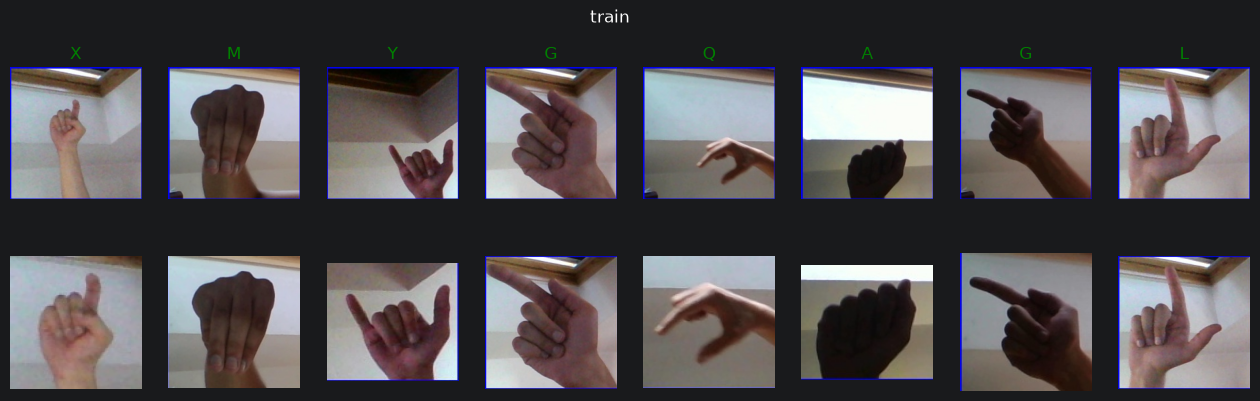

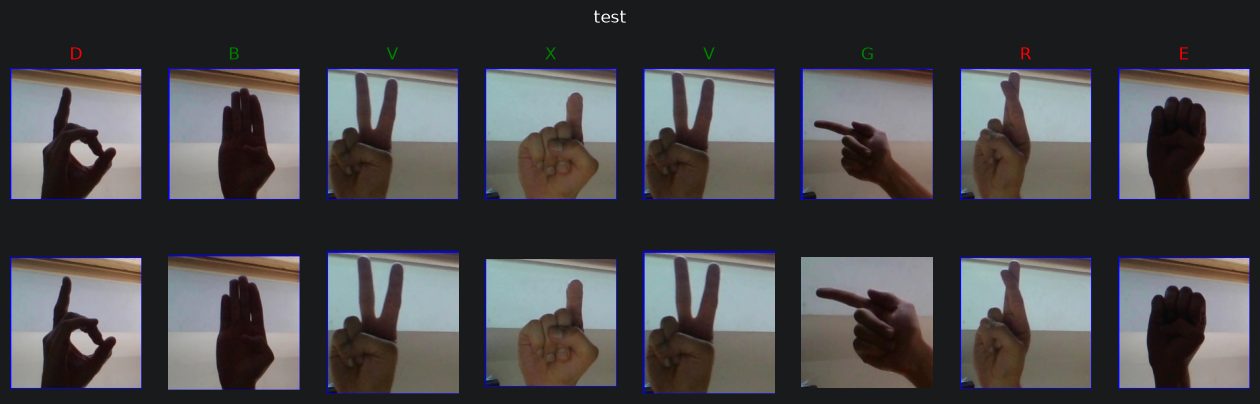

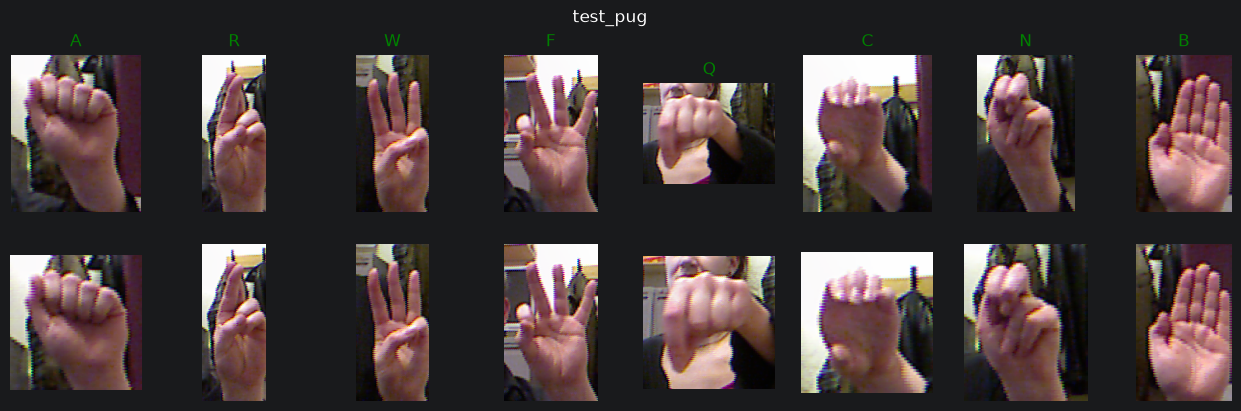

In [23]:
from hand_crop import crop_hand


def show_crops(name, n=8):
    ds = loaders[name].dataset.ds
    idxs = torch.randint(len(ds), (n,)).tolist()
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.5))
    for j, i in enumerate(idxs):
        orig, y = ds.ds[ds.indices[i]]
        box = ds.boxes[i]
        axes[0, j].imshow(orig)
        axes[0, j].set_title(classes[y], color="green" if box else "red")
        axes[1, j].imshow(crop_hand(orig, box, ds.margin))
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(name)
    plt.show()


for name in ("train", "test", "test_pug"):
    show_crops(name)


In [24]:
import torch, torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
from tqdm.auto import tqdm
from torch.optim.lr_scheduler import CosineAnnealingLR

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

torch.manual_seed(42)

model = resnet18(weights=ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
lossFn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.001)
scheduler = CosineAnnealingLR(optimizer, T_max=5, eta_min=0)


def runEpoch(loader, train):
    model.train(train)
    total, loss_sum, correct = 0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in tqdm(loader, leave=False):
            xb, yb = xb.to(device), yb.to(device)
            output = model(xb)
            loss = lossFn(output, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(yb)
            correct += (output.argmax(1) == yb).sum().item()
            total += len(yb)

    return loss_sum / total, correct / total

bestValid = 0
for epoch in range(5):
    trainLoss, trainAcc = runEpoch(train_loader, True)
    validLoss, validAcc = runEpoch(valid_loader, False)
    pugLoss, pugAcc = runEpoch(valid_pug_loader, False)
    print(f"Epoch {epoch}: train loss {trainLoss:.3f} acc {trainAcc:.3f} | "
          f"valid loss {validLoss:.3f} acc {validAcc:.3f} | "
          f"valid Pugeault A-B loss {pugLoss:.3f} acc {pugAcc:.3f}")
    scheduler.step()

    if pugAcc > bestValid:
        bestValid = pugAcc
        torch.save(model.state_dict(), "resnet18_best.pt")

results = []
model.load_state_dict(torch.load("resnet18_best.pt"))
for loader in [test_loader, test_pug_loader]:
    _, testAcc = runEpoch(loader, False)
    results.append(testAcc)
    print(testAcc)
print(bestValid)




  0%|          | 0/585 [00:00<?, ?it/s]

  0%|          | 0/147 [00:00<?, ?it/s]

  0%|          | 0/207 [00:00<?, ?it/s]

Epoch 0: train loss 0.374 acc 0.901 | valid loss 0.034 acc 0.992 | valid Pugeault A-B loss 2.280 acc 0.432


  0%|          | 0/585 [00:00<?, ?it/s]

  0%|          | 0/147 [00:00<?, ?it/s]

... (14 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

1.0


  0%|          | 0/308 [00:00<?, ?it/s]

0.48094281573393677


Grad-CAM target layer: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


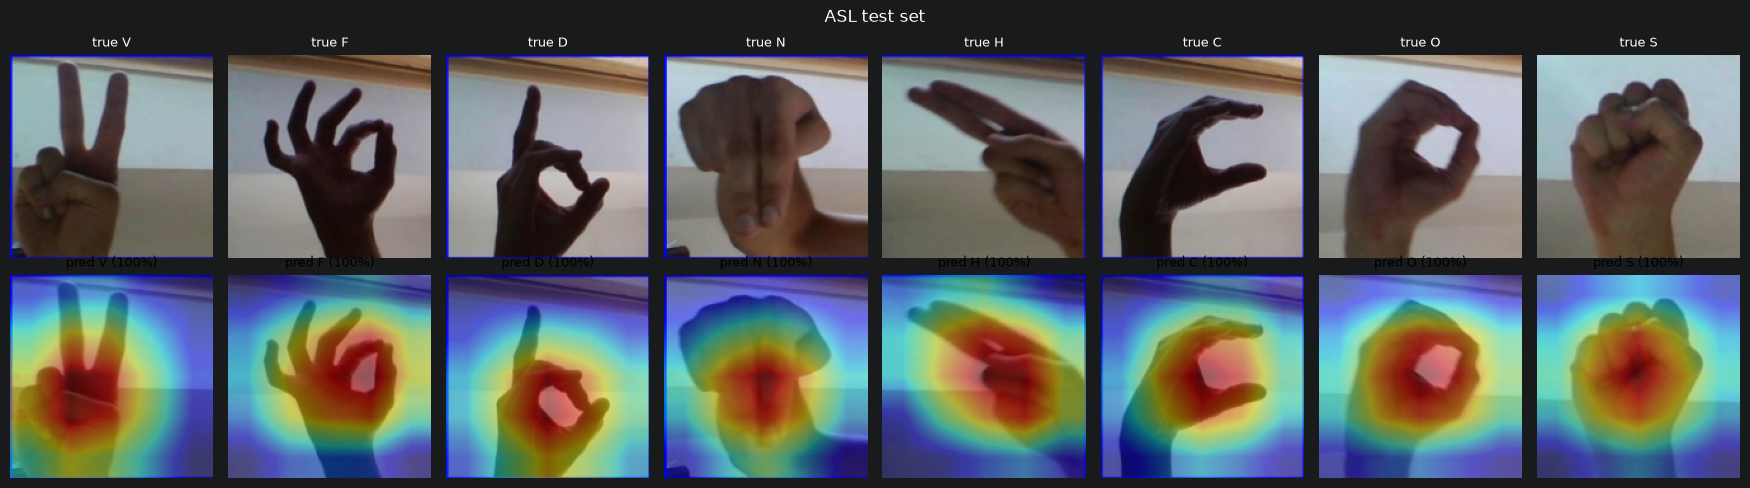

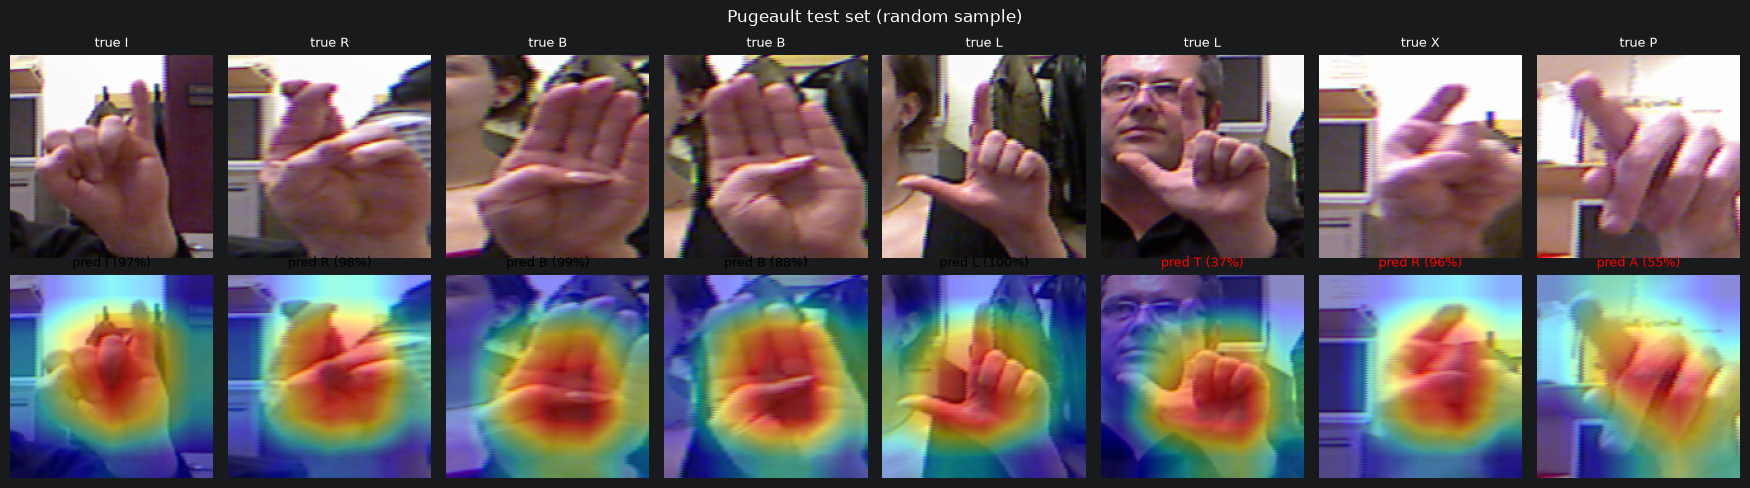

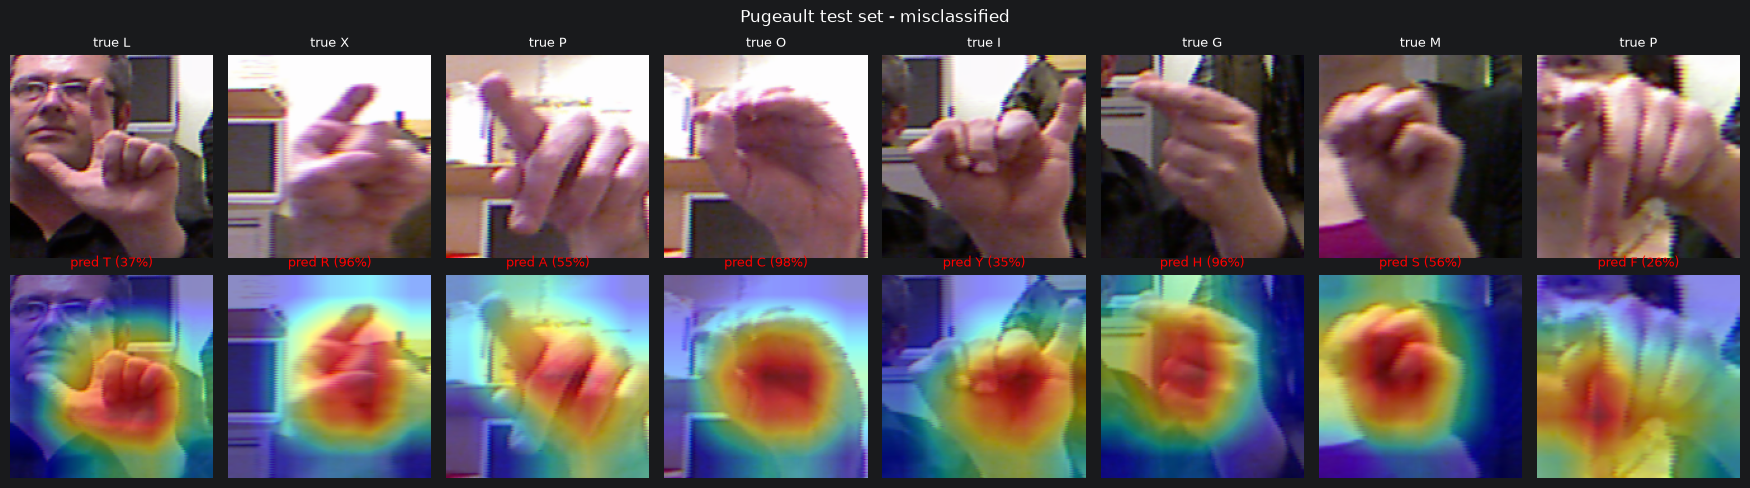

In [25]:
import json
from grad_cam import (GradCAM, find_last_conv, show_gradcam, show_compare_classes,
                      show_class_cams, hand_energy, summarize_energy)

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

assert "model" in globals(), "train or load the model first"
model.eval()
target_layer = find_last_conv(model)
print("Grad-CAM target layer:", target_layer)

show_gradcam(model, target_layer, test_loader, classes, n=8, mean=MEAN, std=STD, seed=0,
             title="ASL test set")
show_gradcam(model, target_layer, test_pug_loader, classes, n=8, mean=MEAN, std=STD, seed=0,
             title="Pugeault test set (random sample)")
show_gradcam(model, target_layer, test_pug_loader, classes, n=8, only="wrong", mean=MEAN, std=STD,
             seed=0, title="Pugeault test set - misclassified")

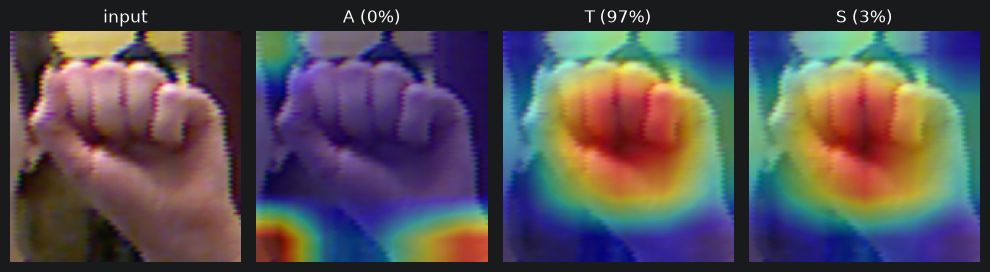

In [26]:
image, label = test_pug_loader.dataset[0]
with torch.no_grad():
    probs = model(image.unsqueeze(0).to(device)).softmax(1)[0].cpu()
top = [i for i in probs.argsort(descending=True).tolist() if i != label][:2]
show_compare_classes(model, target_layer, image, classes, [classes[label]] + [classes[i] for i in top],
                     mean=MEAN, std=STD)

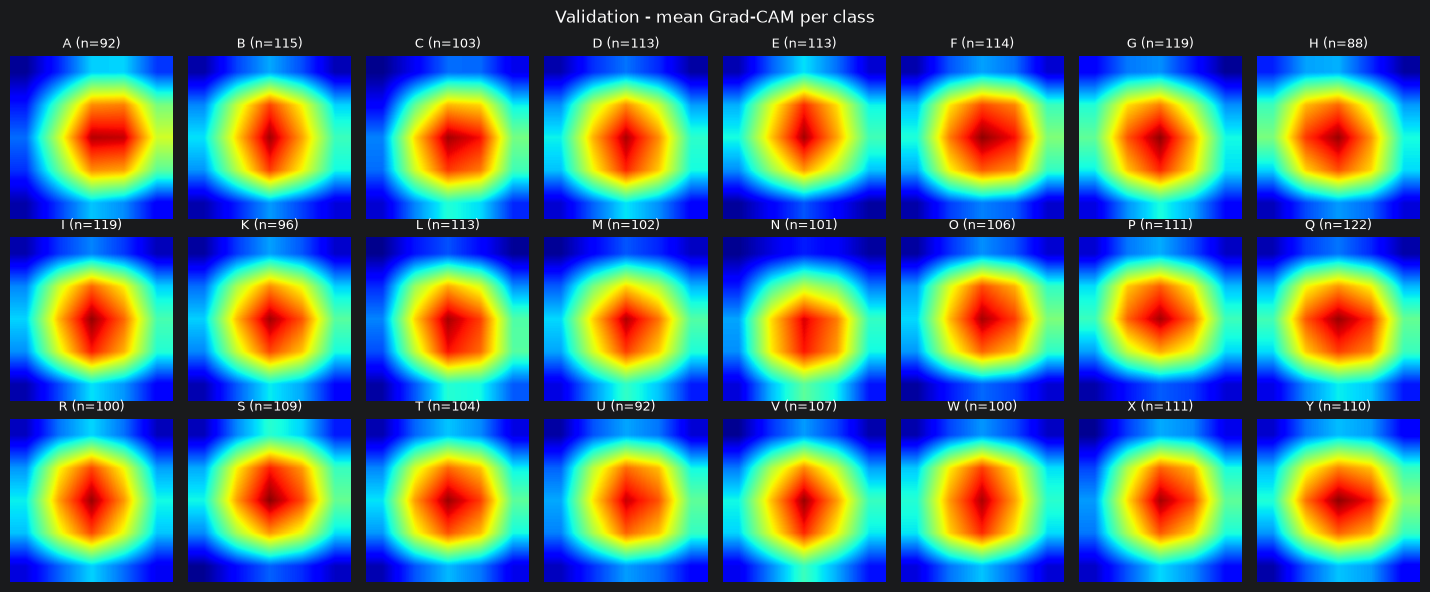

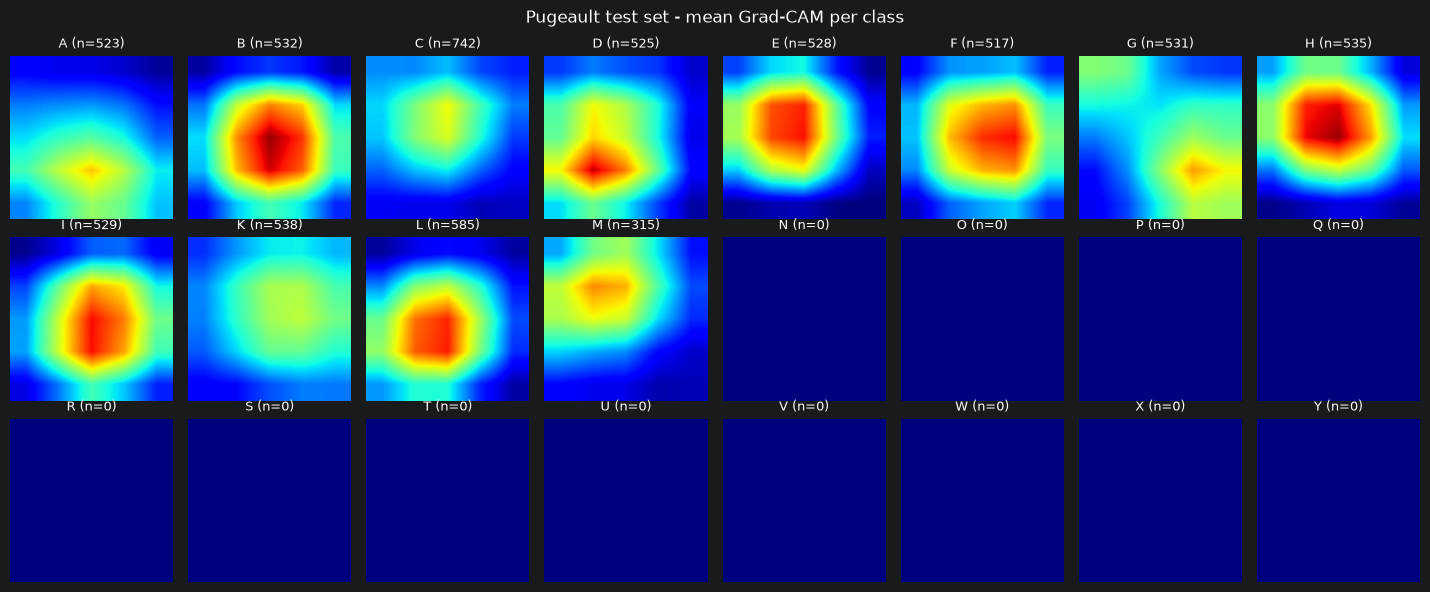

In [27]:
_ = show_class_cams(model, target_layer, valid_loader, classes, max_batches=20,
                    title="Validation - mean Grad-CAM per class")
_ = show_class_cams(model, target_layer, test_pug_loader, classes, max_batches=50,
                    title="Pugeault test set - mean Grad-CAM per class")

In [28]:
boxes = json.loads(HAND_BOXES_CACHE.read_text())
models = globals().get("models") or {"model": (model, loaders)}

results = {}
for name, (m, lds) in models.items():
    layer = find_last_conv(m)
    for split in ("valid", "valid_pug", "test", "test_pug"):
        results[f"{name}/{split}"] = hand_energy(m, layer, lds[split], boxes, max_batches=20)
summarize_energy(results)

model/data                        n   energy  box area  ratio  E|right  E|wrong
model/valid                    2254     0.51      0.32   1.61     0.51     0.46
model/valid_pug                2556     0.63      0.45   1.41     0.67     0.61
model/test                       19     0.56      0.36   1.57     0.56      nan
model/test_pug                 2542     0.57      0.37   1.52     0.61     0.54
